In [1]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

from torch_geometric.data import Data
from torch_geometric.utils import (
    remove_self_loops,
    to_undirected
)
from torch_geometric.nn import (
    GCNConv, GATv2Conv, GINConv, BatchNorm
)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

nx_graph = nx.read_graphml(
    "airportsAndCoordAndPop.graphml"
)

print("Nœuds :", nx_graph.number_of_nodes())
print("Arêtes :", nx_graph.number_of_edges())
print("Device :", device)
print("Exemple :", next(iter(nx_graph.nodes(data=True))))


Nœuds : 3363
Arêtes : 13547
Device : cpu
Exemple : ('0', {'lon': -145.50972222222222, 'lat': -17.35388888888889, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Anaa'})


In [2]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Conserver uniquement les nœuds exploitables
valid_nodes = []
features = []
countries = []

for node, attrs in nx_graph.nodes(data=True):
    try:
        lon = float(attrs["lon"])
        lat = float(attrs["lat"])
        country = str(attrs["country"]).strip()

        if not np.isfinite(lon) or not np.isfinite(lat):
            continue

        if not (-180 <= lon <= 180 and -90 <= lat <= 90):
            continue

        if country.upper() in ["", "UNKNOWN", "NONE", "NAN"]:
            continue

        valid_nodes.append(node)
        features.append([lon, lat])
        countries.append(country)

    except (KeyError, ValueError, TypeError):
        continue

print("Nœuds conservés :", len(valid_nodes))
print("Nœuds exclus :", nx_graph.number_of_nodes() - len(valid_nodes))

encoder = LabelEncoder()
labels = encoder.fit_transform(countries)

node_to_idx = {
    node: i for i, node in enumerate(valid_nodes)
}

edges = []
for u, v in nx_graph.edges():
    if u in node_to_idx and v in node_to_idx:
        edges.append([node_to_idx[u], node_to_idx[v]])

if len(edges) == 0:
    raise ValueError("Aucune arête exploitable dans le graphe.")

edge_index = torch.tensor(
    edges, dtype=torch.long
).t().contiguous()

# Hypothèse : connexions aériennes non orientées
edge_index = to_undirected(
    edge_index, num_nodes=len(valid_nodes)
)

raw_x = torch.tensor(features, dtype=torch.float)
raw_y = torch.tensor(labels, dtype=torch.long)

num_classes = len(encoder.classes_)

print("Nombre de pays :", num_classes)
print("Features :", raw_x.shape)
print("Arêtes PyG :", edge_index.shape[1])


def prepare_data(seed):
    set_seed(seed)

    n = len(raw_y)
    indices = torch.randperm(n)

    n_train = int(0.70 * n)
    n_val = int(0.15 * n)

    train_idx = indices[:n_train]
    val_idx = indices[n_train:n_train+n_val]
    test_idx = indices[n_train+n_val:]

    masks = {}

    for name, idx in [
        ("train", train_idx),
        ("val", val_idx),
        ("test", test_idx)
    ]:
        mask = torch.zeros(n, dtype=torch.bool)
        mask[idx] = True
        masks[name] = mask

    # Normalisation calculée uniquement sur le train
    mean = raw_x[masks["train"]].mean(dim=0)
    std = raw_x[masks["train"]].std(dim=0).clamp(min=1e-6)

    x = (raw_x - mean) / std

    data = Data(
        x=x,
        y=raw_y.clone(),
        edge_index=edge_index,
        train_mask=masks["train"],
        val_mask=masks["val"],
        test_mask=masks["test"]
    )

    return data.to(device)


data = prepare_data(seed=42)

print("Train :", int(data.train_mask.sum()))
print("Validation :", int(data.val_mask.sum()))
print("Test :", int(data.test_mask.sum()))

train_classes = set(data.y[data.train_mask].cpu().tolist())
test_classes = set(data.y[data.test_mask].cpu().tolist())

print("Pays test absents du train :",
      len(test_classes - train_classes))


Nœuds conservés : 3363
Nœuds exclus : 0
Nombre de pays : 212
Features : torch.Size([3363, 2])
Arêtes PyG : 27094
Train : 2354
Validation : 504
Test : 505
Pays test absents du train : 12


In [3]:
class SimpleMLP(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()

        self.lin1 = torch.nn.Linear(in_channels, hidden_channels)
        self.lin2 = torch.nn.Linear(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.lin1(x)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        return self.lin2(x)


class SimpleGCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()

        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        return self.conv2(x, edge_index)


class SimpleGAT(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels,
                 out_channels, heads=4):
        super().__init__()

        self.conv1 = GATv2Conv(
            in_channels, hidden_channels,
            heads=heads, concat=True
        )

        self.conv2 = GATv2Conv(
            hidden_channels * heads,
            out_channels,
            heads=1, concat=False
        )

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        return self.conv2(x, edge_index)


class ImprovedGIN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels,
                 out_channels, use_bn=True):
        super().__init__()

        self.use_bn = use_bn

        mlp1 = torch.nn.Sequential(
            torch.nn.Linear(in_channels, hidden_channels),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_channels, hidden_channels)
        )

        mlp2 = torch.nn.Sequential(
            torch.nn.Linear(hidden_channels, hidden_channels),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_channels, hidden_channels)
        )

        self.conv1 = GINConv(mlp1, train_eps=True)
        self.conv2 = GINConv(mlp2, train_eps=True)

        self.bn1 = BatchNorm(hidden_channels)
        self.bn2 = BatchNorm(hidden_channels)

        self.classifier = torch.nn.Linear(
            hidden_channels, out_channels
        )

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)

        if self.use_bn:
            x = self.bn1(x)

        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        x = self.conv2(x, edge_index)

        if self.use_bn:
            x = self.bn2(x)

        x = F.relu(x)
        return self.classifier(x)


In [4]:
def train_and_evaluate(
    model, data, lr=0.005, epochs=300, patience=40
):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=5e-4
    )

    criterion = torch.nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        logits = model(data.x, data.edge_index)

        loss = criterion(
            logits[data.train_mask],
            data.y[data.train_mask]
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Loss non finie à l'epoch {epoch}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        model.eval()

        with torch.no_grad():
            logits = model(data.x, data.edge_index)

            val_loss = criterion(
                logits[data.val_mask],
                data.y[data.val_mask]
            ).item()

        history["train_loss"].append(loss.item())
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    if best_state is None:
        raise RuntimeError("Aucun modèle valide obtenu.")

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        logits = model(data.x, data.edge_index)
        pred = logits[data.test_mask].argmax(dim=1)
        true = data.y[data.test_mask]

    y_true = true.cpu().numpy()
    y_pred = pred.cpu().numpy()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            labels=np.arange(num_classes),
            zero_division=0
        ),
        "balanced_acc": balanced_accuracy_score(
            y_true, y_pred
        ),
        "best_epoch": best_epoch,
        "history": history
    }


In [5]:
SEEDS = [42, 123, 456, 789, 2026]

model_configs = {
    "MLP": lambda: SimpleMLP(2, 64, num_classes),
    "GCN": lambda: SimpleGCN(2, 64, num_classes),
    "GATv2": lambda: SimpleGAT(2, 32, num_classes, heads=4),
    "GIN_BN": lambda: ImprovedGIN(2, 64, num_classes)
}

all_results = []

for seed in SEEDS:
    print(f"\n SEED {seed} ")

    data = prepare_data(seed)

    for name, create_model in model_configs.items():
        set_seed(seed)

        model = create_model().to(device)

        scores = train_and_evaluate(
            model, data,
            lr=0.005,
            epochs=300,
            patience=40
        )

        all_results.append({
            "Seed": seed,
            "Modèle": name,
            "Accuracy": scores["accuracy"],
            "Macro-F1": scores["macro_f1"],
            "Balanced Accuracy": scores["balanced_acc"],
            "Best Epoch": scores["best_epoch"]
        })

        print(
            f"{name:7s} | "
            f"Acc: {scores['accuracy']:.4f} | "
            f"F1: {scores['macro_f1']:.4f} | "
            f"Epoch: {scores['best_epoch']}"
        )

df_results = pd.DataFrame(all_results)

summary = df_results.groupby("Modèle").agg({
    "Accuracy": ["mean", "std"],
    "Macro-F1": ["mean", "std"],
    "Balanced Accuracy": ["mean", "std"]
})

print("\n RÉSULTATS MOYENS SUR 5 SEEDS ")
print(summary.round(4))

df_results.to_csv("resultats_gnn.csv", index=False)



 SEED 42 
MLP     | Acc: 0.5465 | F1: 0.0864 | Epoch: 300
GCN     | Acc: 0.4772 | F1: 0.0651 | Epoch: 300
GATv2   | Acc: 0.6792 | F1: 0.1715 | Epoch: 300
GIN_BN  | Acc: 0.5683 | F1: 0.1443 | Epoch: 174

 SEED 123 
MLP     | Acc: 0.6139 | F1: 0.0919 | Epoch: 300
GCN     | Acc: 0.5347 | F1: 0.0637 | Epoch: 299
GATv2   | Acc: 0.7050 | F1: 0.1812 | Epoch: 300
GIN_BN  | Acc: 0.6455 | F1: 0.1621 | Epoch: 283

 SEED 456 
MLP     | Acc: 0.6238 | F1: 0.0896 | Epoch: 300
GCN     | Acc: 0.5762 | F1: 0.0747 | Epoch: 300
GATv2   | Acc: 0.7267 | F1: 0.1692 | Epoch: 285
GIN_BN  | Acc: 0.6455 | F1: 0.1554 | Epoch: 280

 SEED 789 
MLP     | Acc: 0.5663 | F1: 0.0924 | Epoch: 300
GCN     | Acc: 0.4851 | F1: 0.0666 | Epoch: 300
GATv2   | Acc: 0.6673 | F1: 0.1799 | Epoch: 297
GIN_BN  | Acc: 0.6416 | F1: 0.1872 | Epoch: 300

 SEED 2026 
MLP     | Acc: 0.6079 | F1: 0.0998 | Epoch: 300
GCN     | Acc: 0.4891 | F1: 0.0598 | Epoch: 300
GATv2   | Acc: 0.6851 | F1: 0.1672 | Epoch: 299
GIN_BN  | Acc: 0.6158 | F1: 

In [6]:
ablation_results = []

for seed in SEEDS:
    data = prepare_data(seed)

    # Conserver les arêtes originales
    original_edges = data.edge_index.clone()

    # GATv2 conserve ses self-loops
    empty_edges = torch.empty(
        (2, 0),
        dtype=torch.long,
        device=device
    )

    # Graphe aléatoire 
    # On repart des arêtes sans self-loops
    edges_no_loop, _ = remove_self_loops(original_edges)

    set_seed(seed)
    permutation = torch.randperm(
        edges_no_loop.size(1),
        device=device
    )

    random_edges = torch.stack([
        edges_no_loop[0],
        edges_no_loop[1][permutation]
    ])

    random_edges = to_undirected(
        random_edges,
        num_nodes=data.num_nodes
    )

    configurations = {
        "GATv2 complet": original_edges,
        "Sans arêtes": empty_edges,
        "Arêtes aléatoires": random_edges
    }

    for name, edges in configurations.items():
        set_seed(seed)

        model = SimpleGAT(
            2, 32, num_classes, heads=4
        ).to(device)

        data.edge_index = edges

        scores = train_and_evaluate(
            model, data,
            lr=0.005,
            epochs=300,
            patience=40
        )

        ablation_results.append({
            "Seed": seed,
            "Configuration": name,
            "Accuracy": scores["accuracy"],
            "Macro-F1": scores["macro_f1"],
            "Balanced Accuracy": scores["balanced_acc"]
        })

        print(
            f"Seed {seed} | {name} | "
            f"Accuracy : {scores['accuracy']:.4f}"
        )

    data.edge_index = original_edges

df_ablation_gat = pd.DataFrame(ablation_results)

print("\n ABLATION GATv2")
print(
    df_ablation_gat.groupby("Configuration")[
        ["Accuracy", "Macro-F1", "Balanced Accuracy"]
    ].agg(["mean", "std"]).round(4)
)


Seed 42 | GATv2 complet | Accuracy : 0.6792
Seed 42 | Sans arêtes | Accuracy : 0.5683
Seed 42 | Arêtes aléatoires | Accuracy : 0.5624
Seed 123 | GATv2 complet | Accuracy : 0.7050
Seed 123 | Sans arêtes | Accuracy : 0.6356
Seed 123 | Arêtes aléatoires | Accuracy : 0.5941
Seed 456 | GATv2 complet | Accuracy : 0.7267
Seed 456 | Sans arêtes | Accuracy : 0.6356
Seed 456 | Arêtes aléatoires | Accuracy : 0.6059
Seed 789 | GATv2 complet | Accuracy : 0.6673
Seed 789 | Sans arêtes | Accuracy : 0.5663
Seed 789 | Arêtes aléatoires | Accuracy : 0.5505
Seed 2026 | GATv2 complet | Accuracy : 0.6851
Seed 2026 | Sans arêtes | Accuracy : 0.6119
Seed 2026 | Arêtes aléatoires | Accuracy : 0.5881

 ABLATION GATv2
                  Accuracy         Macro-F1         Balanced Accuracy        
                      mean     std     mean     std              mean     std
Configuration                                                                
Arêtes aléatoires   0.5802  0.0230   0.0970  0.0083            0


SEED : 42 
Heads=1 | Accuracy=0.5109 | Macro-F1=0.0678 | Balanced Acc=0.1763
Heads=2 | Accuracy=0.5842 | Macro-F1=0.1102 | Balanced Acc=0.2478
Heads=4 | Accuracy=0.6792 | Macro-F1=0.1715 | Balanced Acc=0.3625
Heads=8 | Accuracy=0.7168 | Macro-F1=0.1944 | Balanced Acc=0.4143

SEED : 123 
Heads=1 | Accuracy=0.5604 | Macro-F1=0.0671 | Balanced Acc=0.1763
Heads=2 | Accuracy=0.5941 | Macro-F1=0.0810 | Balanced Acc=0.2100
Heads=4 | Accuracy=0.7050 | Macro-F1=0.1812 | Balanced Acc=0.3925
Heads=8 | Accuracy=0.7426 | Macro-F1=0.2147 | Balanced Acc=0.4487

SEED : 456 
Heads=1 | Accuracy=0.5921 | Macro-F1=0.0751 | Balanced Acc=0.1989
Heads=2 | Accuracy=0.6653 | Macro-F1=0.1095 | Balanced Acc=0.2604
Heads=4 | Accuracy=0.7267 | Macro-F1=0.1692 | Balanced Acc=0.3780
Heads=8 | Accuracy=0.7723 | Macro-F1=0.2274 | Balanced Acc=0.5018

SEED : 789 
Heads=1 | Accuracy=0.4950 | Macro-F1=0.0643 | Balanced Acc=0.1616
Heads=2 | Accuracy=0.5822 | Macro-F1=0.1265 | Balanced Acc=0.2770
Heads=4 | Accuracy=0.6673

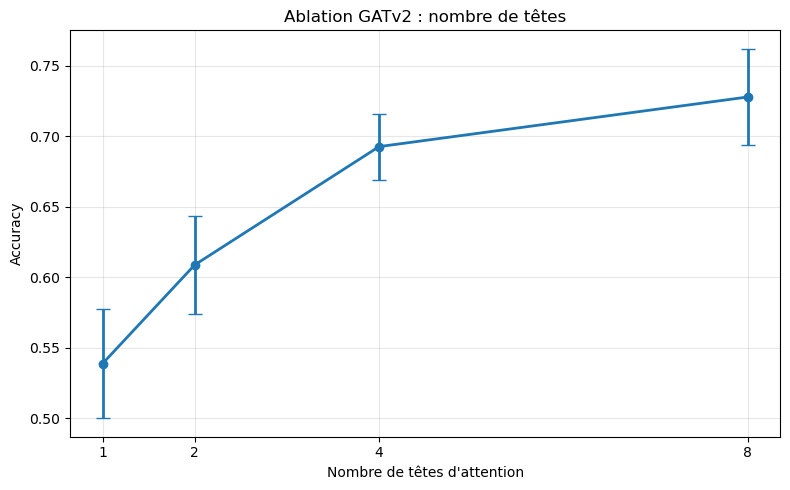

In [7]:
HEADS = [1, 2, 4, 8]
SEEDS = [42, 123, 456, 789, 2026]

heads_results = []

for seed in SEEDS:

    print(f"\nSEED : {seed} ")

    # Même découpage pour chaque nombre de têtes
    data = prepare_data(seed)

    for heads in HEADS:

        # Reproductibilité
        set_seed(seed)

        model = SimpleGAT(
            in_channels=2,
            hidden_channels=32,
            out_channels=num_classes,
            heads=heads
        ).to(device)

        scores = train_and_evaluate(
            model,
            data,
            lr=0.005,
            epochs=300,
            patience=40
        )

        heads_results.append({
            "Seed": seed,
            "Heads": heads,
            "Accuracy": scores["accuracy"],
            "Macro-F1": scores["macro_f1"],
            "Balanced Accuracy": scores["balanced_acc"],
            "Best Epoch": scores["best_epoch"]
        })

        print(
            f"Heads={heads} | "
            f"Accuracy={scores['accuracy']:.4f} | "
            f"Macro-F1={scores['macro_f1']:.4f} | "
            f"Balanced Acc={scores['balanced_acc']:.4f}"
        )


df_heads = pd.DataFrame(heads_results)

summary_heads = df_heads.groupby("Heads")[
    ["Accuracy", "Macro-F1", "Balanced Accuracy"]
].agg(["mean", "std"])

print("\n ABLATION NOMBRE DE TÊTES ")
print(summary_heads.round(4))




acc_mean = df_heads.groupby("Heads")["Accuracy"].mean()
acc_std = df_heads.groupby("Heads")["Accuracy"].std()

plt.figure(figsize=(8, 5))

plt.errorbar(
    acc_mean.index,
    acc_mean.values,
    yerr=acc_std.values,
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xlabel("Nombre de têtes d'attention")
plt.ylabel("Accuracy")
plt.title("Ablation GATv2 : nombre de têtes")
plt.xticks(HEADS)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Sauvegarde des résultats
df_heads.to_csv(
    "ablation_heads_gatv2.csv",
    index=False
)


In [8]:
HEADS = [1, 2, 4, 8]
TOTAL_DIM = 128

fixed_dim_results = []

for seed in SEEDS:
    data = prepare_data(seed)

    for heads in HEADS:
        set_seed(seed)

        # TOTAL DIMENSION = 128
        hidden_per_head = TOTAL_DIM // heads

        model = SimpleGAT(
            in_channels=2,
            hidden_channels=hidden_per_head,
            out_channels=num_classes,
            heads=heads
        ).to(device)

        scores = train_and_evaluate(
            model,
            data,
            lr=0.005,
            epochs=300,
            patience=40
        )

        fixed_dim_results.append({
            "Seed": seed,
            "Heads": heads,
            "Hidden per head": hidden_per_head,
            "Parameters": sum(
                p.numel() for p in model.parameters()
            ),
            "Accuracy": scores["accuracy"],
            "Macro-F1": scores["macro_f1"],
            "Balanced Accuracy": scores["balanced_acc"]
        })

df_fixed = pd.DataFrame(fixed_dim_results)

print("\n ABLATION DIMENSION CONSTANTE ")

print(
    df_fixed.groupby("Heads")[
        ["Parameters", "Accuracy",
         "Macro-F1", "Balanced Accuracy"]
    ].agg(["mean", "std"]).round(4)
)

df_fixed.to_csv(
    "ablation_gat_fixed_dim.csv",
    index=False
)



 ABLATION DIMENSION CONSTANTE 
      Parameters      Accuracy         Macro-F1         Balanced Accuracy  \
            mean  std     mean     std     mean     std              mean   
Heads                                                                       
1        56144.0  0.0   0.6226  0.0294   0.1034  0.0020            0.2451   
2        56144.0  0.0   0.6566  0.0213   0.1377  0.0053            0.3055   
4        56144.0  0.0   0.6927  0.0234   0.1738  0.0064            0.3716   
8        56144.0  0.0   0.6883  0.0279   0.1769  0.0114            0.3767   

               
          std  
Heads          
1      0.0105  
2      0.0164  
4      0.0178  
8      0.0178  
